# DQN deep dive — from CartPole to a quadrotor

**Companion notebook to the lecture slides** (`DQN_deep_dive_lecture.pptx`). Follows the PPO deep dive and uses the same planar
quadrotor, so the two algorithms can be compared on one task.

Everything here is written from scratch in PyTorch + NumPy — no RL library — and every number quoted in the slides is
computed below.

### Learning objectives
By the end you should be able to:
1. Write the DQN target $y = r + \gamma \max_{a'} Q(s', a'; \theta^-)$ and explain each piece of it.
2. Explain *why* a replay buffer and a target network are needed, and recognise the failure when one is missing.
3. Quantify **overestimation bias** and show how Double Q-learning removes it.
4. Implement Double DQN, a dueling head, n-step returns and prioritised replay, and **measure** what each contributes.
5. Apply DQN to a continuous-control task by designing an action menu and a decision rate, and compare it fairly with PPO.
6. Read a DQN diagnostics dashboard (max-Q, |TD error|, gradient norm) and diagnose a broken run.

### Prerequisites
Q-learning and the Bellman equation (RL lecture), PyTorch `nn.Module` / autograd, and ideally the PPO deep dive.

### Runtime
About **15 minutes on 2 CPU cores**: 30 CartPole runs (10 variants × 3 seeds, ~25 s each) and 15 quadrotor runs.
Set `QUICK = True` in the next cell to use one seed (~5 min); the conclusions hold but the numbers will differ from the slides.

In [1]:
QUICK = False          # True: one seed per experiment (~5 min) instead of three (~15 min)
SEEDS = [0] if QUICK else [0, 1, 2]

import sys, platform, time, copy, math, json
from collections import deque
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib, matplotlib.pyplot as plt
import multiprocessing as mp
torch.set_num_threads(1)               # one thread per run: faster with 2 workers, and reproducible
print("python", platform.python_version(), "| numpy", np.__version__, "| torch", torch.__version__,
      "| matplotlib", matplotlib.__version__)

BLUE, ORANGE, AQUA, YELLOW, RED, VIOLET, INK, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e34948", "#4a3aa7", "#0b0b0b", "#898781"
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.grid": True, "grid.color": "#e1e0d9",
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False, "font.size": 10.5})

python 3.13.18 | numpy 2.5.3 | torch 2.15.0+cu132 | matplotlib 3.11.2


## 1. Two environments

**CartPole** (Barto, Sutton & Anderson 1983) is the classic DQN test bed: 4 state variables, 2 actions (push left / right),
+1 reward per step, failure when the pole passes 12° or the cart leaves the track, and a 500-step time-out. It trains in
~25 s, so we can afford 3 seeds of 10 variants — which is what an honest ablation needs.

**The planar quadrotor** is the same model as in the PPO deep dive: 0.80 kg, 0.17 m arm, 30 ms first-order motor lag, 50 Hz
physics, 250-step (5 s) episodes, crash = −10 and the episode ends. PPO commands the two thrusts continuously; DQN needs a
**menu** of discrete actions, which is the first design decision we have to make.

Both environments are vectorised (many copies stepped at once with NumPy) and **auto-reset**. On a *time-out* `step()`
returns the true last observation in `final`, so the learner can bootstrap from it — a time-out is not a terminal state.

In [2]:
class CartPole:
    '''Vectorised CartPole (Barto, Sutton & Anderson 1983; same constants as Gymnasium CartPole-v1).
    Reward +1 per step; terminates when |x| > 2.4 m or |theta| > 12 deg; truncates at max_steps.
    step() auto-resets finished envs and returns final_obs so time-outs can be bootstrapped.'''
    obs_dim, n_actions = 4, 2
    G, MC, MP, L, FORCE, DT = 9.8, 1.0, 0.1, 0.5, 10.0, 0.02
    X_LIM, TH_LIM = 2.4, 12 * 2 * math.pi / 360

    repeat = 1
    def __init__(self, n=4, seed=0, max_steps=500, repeat=1):
        self.n, self.max_steps = n, max_steps
        self.rng = np.random.default_rng(seed)
        self.s = np.zeros((n, 4)); self.t = np.zeros(n, int)

    def _reset_idx(self, idx):
        self.s[idx] = self.rng.uniform(-0.05, 0.05, (len(idx), 4)); self.t[idx] = 0

    def reset(self):
        self._reset_idx(np.arange(self.n)); return self.s.copy()

    def step(self, a):
        x, xd, th, thd = self.s.T
        f = np.where(a == 1, self.FORCE, -self.FORCE)
        ct, st = np.cos(th), np.sin(th)
        mt, pml = self.MC + self.MP, self.MP * self.L
        tmp = (f + pml * thd**2 * st) / mt
        thacc = (self.G * st - ct * tmp) / (self.L * (4/3 - self.MP * ct**2 / mt))
        xacc = tmp - pml * thacc * ct / mt
        x = x + self.DT * xd; xd = xd + self.DT * xacc
        th = th + self.DT * thd; thd = thd + self.DT * thacc
        self.s = np.stack([x, xd, th, thd], 1); self.t += 1
        term = (np.abs(x) > self.X_LIM) | (np.abs(th) > self.TH_LIM)
        trunc = (self.t >= self.max_steps) & ~term
        r = np.ones(self.n)
        final = self.s.copy()
        done = np.flatnonzero(term | trunc)
        if len(done): self._reset_idx(done)
        return self.s.copy(), r, term, trunc, final

class PlanarQuad:
    '''Planar (2-D) quadrotor, 50 Hz, 250-step episodes - same model as the PPO deep dive.
    State x, z, theta, xd, zd, omega and two motor thrusts with a 30 ms first-order lag.
    Action u in [-1, 1]^2: commanded thrust T_i = T_hover (1 + u_i). Target hover point (0, 1.5).
    obs (9): e_x, e_z, sin th, cos th, xd, zd, omega/4, u_prev(2).'''
    obs_dim = 9
    M, ARM, I, DRAG, G, DT, TAU = 0.80, 0.17, 0.006, 0.10, 9.81, 0.02, 0.03
    TARGET = np.array([0.0, 1.5])
    # discrete action set for DQN: collective {-0.3, 0, +0.3} x differential {0, +-0.03, +-0.10}
    ACTIONS = np.array([[c - d, c + d] for c in (-0.3, 0.0, 0.3) for d in (-0.10, -0.03, 0.0, 0.03, 0.10)])
    n_actions = 15

    def __init__(self, n=8, seed=0, max_steps=250, repeat=1):
        self.n, self.max_steps, self.repeat = n, max_steps, repeat
        self.rng = np.random.default_rng(seed)
        self.T_h = self.M * self.G / 2
        self.s = np.zeros((n, 6)); self.T = np.full((n, 2), self.T_h)
        self.u_prev = np.zeros((n, 2)); self.t = np.zeros(n, int)

    def _reset_idx(self, idx):
        k = len(idx); r = self.rng
        self.s[idx] = np.stack([r.uniform(-1, 1, k), r.uniform(0.7, 2.3, k), r.uniform(-0.3, 0.3, k),
                                r.uniform(-0.3, 0.3, k), r.uniform(-0.3, 0.3, k), r.uniform(-0.5, 0.5, k)], 1)
        self.T[idx] = self.T_h; self.u_prev[idx] = 0; self.t[idx] = 0

    def obs(self):
        x, z, th, xd, zd, om = self.s.T
        return np.stack([x - self.TARGET[0], z - self.TARGET[1], np.sin(th), np.cos(th),
                         xd, zd, om / 4, self.u_prev[:, 0], self.u_prev[:, 1]], 1)

    def reset(self):
        self._reset_idx(np.arange(self.n)); return self.obs()

    def _physics(self, u):
        Tc = self.T_h * (1 + u)
        self.T += (self.DT / self.TAU) * (Tc - self.T)
        x, z, th, xd, zd, om = self.s.T
        Ft = self.T.sum(1)
        xdd = (-Ft * np.sin(th) - self.DRAG * xd) / self.M
        zdd = (Ft * np.cos(th) - self.DRAG * zd) / self.M - self.G
        omd = self.ARM * (self.T[:, 1] - self.T[:, 0]) / self.I
        xd = xd + self.DT * xdd; zd = zd + self.DT * zdd; om = om + self.DT * omd
        x = x + self.DT * xd; z = z + self.DT * zd; th = th + self.DT * om
        self.s = np.stack([x, z, th, xd, zd, om], 1)

    def step(self, u):
        '''One decision: the action is held for `repeat` physics steps (20 ms each).
        Rewards of the sub-steps are summed; a crash ends the decision immediately.'''
        u = np.asarray(u)
        if u.ndim == 1: u = self.ACTIONS[u.astype(int)]          # discrete index -> thrusts
        u = np.clip(u.astype(float), -1, 1)
        du = np.abs(u - self.u_prev).sum(1); self.u_prev = u.copy()
        R = np.zeros(self.n); term = np.zeros(self.n, bool); live = np.ones(self.n, bool)
        for k in range(self.repeat):
            s_old = self.s.copy(); T_old = self.T.copy()
            self._physics(u)
            self.s[~live] = s_old[~live]; self.T[~live] = T_old[~live]   # freeze envs that crashed
            x, z, th, xd, zd, om = self.s.T
            e = np.hypot(x - self.TARGET[0], z - self.TARGET[1])
            r = 1 - e - 0.2*np.abs(th) - 0.05*np.hypot(xd, zd) - 0.02*np.abs(om) - (0.05*du if k == 0 else 0)
            crash = live & ((z < 0.05) | (np.abs(x) > 2.5) | (np.abs(th) > 1.4) | (z > 4.0))
            R += np.where(crash, -10.0, np.where(live, r, 0.0))
            term |= crash; live &= ~crash
        self.t += self.repeat
        trunc = (self.t >= self.max_steps) & ~term
        final = self.obs()
        x, z = self.s[:, 0], self.s[:, 1]
        self.info = dict(err=np.hypot(x - self.TARGET[0], z - self.TARGET[1]), du=du)
        done = np.flatnonzero(term | trunc)
        if len(done): self._reset_idx(done)
        return self.obs(), R, term, trunc, final

ENVS = {"cartpole": CartPole, "quad": PlanarQuad}

ENVS = {'cartpole': CartPole, 'quad': PlanarQuad}

The quadrotor's action is a pair $u = (u_1, u_2) \in [-1,1]^2$ and the commanded thrust is $T_i = T_\text{hover}(1+u_i)$.
For DQN we write it as **collective + differential**: $u_1 = c - d,\; u_2 = c + d$ with $c \in \{-0.3, 0, 0.3\}$ and
$d \in \{0, \pm 0.03, \pm 0.10\}$ — 15 actions. The small $\pm 0.03$ levels give fine attitude corrections; the $\pm 0.10$
levels give the authority to recover from a bad start.

Before any learning, two sanity checks: how long does a random policy survive, and can a hand-tuned PD controller hover?
The PD controller is our reference for "good" on the quad.

In [3]:
def pd_quad(E, o):
    '''Cascaded PD hover controller (kp 4, kd 3, kp_theta 60, kd_theta 12) using the nominal model.'''
    ex, ez, s, c, xd, zd, om4 = o[:, :7].T; th = np.arctan2(s, c); om = om4 * 4
    uc = (-4*ez - 3*zd) / 9.81
    th_des = np.clip((4*ex + 3*xd) / 9.81, -0.5, 0.5)
    d = (60*(th_des - th) - 12*om) * E.I / (2 * E.ARM * E.T_h)
    return np.stack([uc - d, uc + d], 1)

def run_pd(action_set=None, n=64, seed=10_000):
    '''Fly the PD controller, optionally snapping each command to the nearest entry of a discrete
    action set - tells you whether that menu of actions can hover the quad at all.'''
    E = PlanarQuad(n=n, seed=seed); o = E.reset(); ret = np.zeros(n); alive = np.ones(n, bool)
    crash = np.zeros(n, bool); du = np.zeros(n); tail = []
    for t in range(E.max_steps):
        u = pd_quad(E, o)
        if action_set is not None:
            u = action_set[np.argmin(((action_set[None] - u[:, None])**2).sum(2), 1)]
        o, r, term, trunc, _ = E.step(u); ret += np.where(alive, r, 0); du += np.where(alive, E.info["du"], 0)
        crash |= term & alive; alive &= ~term
        if t >= E.max_steps - 50: tail.append(np.where(alive, E.info["err"], np.nan))
    et = np.array(tail); ok = ~np.isnan(et)
    err = np.where(ok, et, 0).sum() / max(ok.sum(), 1) if ok.any() else float("nan")
    return dict(ret=ret.mean(), crash=crash.mean(), err=err, chatter=du.mean() / (E.max_steps * E.DT))

COARSE_9 = np.array([[c - d, c + d] for c in (-0.3, 0.0, 0.3) for d in (-0.15, 0.0, 0.15)])

def survive(EnvCls, policy, n=256, seed=3):
    E = EnvCls(n=n, seed=seed); o = E.reset(); r = np.random.default_rng(0)
    alive = np.ones(n, bool); T = np.zeros(n)
    for t in range(E.max_steps):
        o, rew, term, trunc, _ = E.step(policy(o, r)); T += alive; alive &= ~term
    return T.mean()

print(f"CartPole, random policy : survives {survive(CartPole, lambda o, r: r.integers(0, 2, len(o))):.1f} steps of 500")
print(f"Quad, random of 15      : survives {survive(PlanarQuad, lambda o, r: r.integers(0, 15, len(o))):.1f} steps of 250")
pdc = run_pd()
print(f"Quad, continuous PD     : return {pdc['ret']:.1f}, crash rate {pdc['crash']:.0%}, hover error {100*pdc['err']:.2f} cm")

CartPole, random policy : survives 20.8 steps of 500
Quad, random of 15      : survives 63.1 steps of 250
Quad, continuous PD     : return 219.3, crash rate 0%, hover error 0.03 cm


A random quad crashes in about one second, so early ε-greedy data is almost all crashes. Learning has to bootstrap out of
that — and the PD controller tells us what a good return looks like (≈ 219).

## 2. From Q-learning to DQN

Q-learning learns the optimal action value from the Bellman optimality equation

$$Q^*(s,a) = \mathbb{E}\left[r + \gamma \max_{a'} Q^*(s', a') \right].$$

A table works for the 1-D altitude problem of the RL lecture; for 4 or 9 continuous state variables it does not (the RL
lecture computed 171 GB for a 6-D grid). **DQN** (Mnih et al. 2015) replaces the table by a network $Q(s, \cdot\,; \theta)$
that outputs one value per action, and turns the Bellman equation into regression:

$$L(\theta) = \mathbb{E}_{(s,a,r,s') \sim \mathcal{D}} \Big[ \ell\big(y - Q(s,a;\theta)\big) \Big], \qquad
y = r + \gamma (1-\text{done}) \max_{a'} Q(s', a'; \theta^-)$$

Three ingredients make that regression stable enough to work:

| ingredient | what it does | what breaks without it |
|---|---|---|
| **replay buffer** $\mathcal{D}$ | samples old transitions uniformly → decorrelated minibatches, each transition reused many times | consecutive samples are near-identical; the net chases the last few seconds of experience |
| **target network** $\theta^-$ | a frozen copy, refreshed every $C$ updates; the target $y$ stops moving while we regress onto it | the target moves with every step; with bootstrapping + off-policy data + function approximation (the *deadly triad*) Q can diverge |
| **Huber loss** $\ell$ | quadratic near 0, linear beyond 1 → bounded gradients for big TD errors | large early TD errors give large gradient steps (we will see this one matters less than folklore says) |

The network itself is an ordinary MLP. The dueling option is explained in §4.

In [4]:
class QNet(nn.Module):
    '''MLP Q-network. dueling=True splits the last layer into V(s) and A(s,a) streams
    and recombines Q = V + A - mean_a A (Wang et al. 2016).'''
    def __init__(self, obs_dim, n_actions, hidden=(64, 64), dueling=False):
        super().__init__()
        layers, d = [], obs_dim
        for h in hidden: layers += [nn.Linear(d, h), nn.ReLU()]; d = h
        self.body = nn.Sequential(*layers); self.dueling = dueling
        if dueling:
            self.v = nn.Linear(d, 1); self.a = nn.Linear(d, n_actions)
        else:
            self.q = nn.Linear(d, n_actions)

    def forward(self, x):
        h = self.body(x)
        if self.dueling:
            a = self.a(h); return self.v(h) + a - a.mean(1, keepdim=True)
        return self.q(h)

net = QNet(4, 2, (64, 64))
print(net)
print("Q-values for 3 random CartPole states:\n", net(torch.randn(3, 4)).detach().numpy().round(3))
print("parameters:", sum(p.numel() for p in net.parameters()))

QNet(
  (body): Sequential(
    (0): Linear(in_features=4, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
  )
  (q): Linear(in_features=64, out_features=2, bias=True)
)
Q-values for 3 random CartPole states:
 [[-0.033 -0.03 ]
 [ 0.016  0.053]
 [-0.055 -0.115]]
parameters: 4610


## 3. The replay buffer and n-step returns

The buffer is a ring of arrays. Each row stores an **n-step** transition: the discounted sum of the next $k \le n$ rewards,
the state to bootstrap from, a terminal flag, and the discount $\gamma^k$ to apply to the bootstrap:

$$y = \underbrace{r_t + \gamma r_{t+1} + \dots + \gamma^{k-1} r_{t+k-1}}_{\text{stored as } R} \;+\; \gamma^k (1-\text{done}) \max_{a'} Q(s_{t+k}, a'; \theta^-)$$

With $n = 1$ this is plain DQN. With $n = 3$, reward information travels three steps per update instead of one. The cost:
those intermediate rewards came from the old ε-greedy policy, so the target is slightly *off-policy biased*. Rainbow
(Hessel et al. 2018) found $n=3$ a good default.

`alpha > 0` turns on **prioritised experience replay** (PER, Schaul et al. 2016): transitions are sampled with probability
$P(i) \propto p_i^\alpha$ where $p_i = |\delta_i| + \epsilon$ is the last TD error, and the loss is re-weighted by importance
weights $w_i = (N P(i))^{-\beta}$ (annealed $\beta \to 1$) so the update stays unbiased in the limit.

In [5]:
class Replay:
    '''Ring buffer of (obs, action, n-step return, next obs, terminal, discount).
    alpha > 0 turns on proportional prioritised replay (Schaul et al. 2016):
    P(i) ~ p_i^alpha, importance weights w_i = (N P(i))^-beta / max w.'''
    def __init__(self, cap, obs_dim, rng, alpha=0.0):
        self.cap, self.rng, self.alpha = cap, rng, alpha
        self.o = np.zeros((cap, obs_dim), np.float32); self.no = np.zeros_like(self.o)
        self.a = np.zeros(cap, np.int64); self.r = np.zeros(cap, np.float32)
        self.d = np.zeros(cap, np.float32); self.g = np.zeros(cap, np.float32)
        self.p = np.zeros(cap); self.size = 0; self.ptr = 0; self.pmax = 1.0

    def add(self, o, a, r, no, d, g):
        k = len(a); idx = (self.ptr + np.arange(k)) % self.cap
        self.o[idx], self.a[idx], self.r[idx], self.no[idx], self.d[idx], self.g[idx] = o, a, r, no, d, g
        self.p[idx] = self.pmax
        self.ptr = (self.ptr + k) % self.cap; self.size = min(self.size + k, self.cap)

    def sample(self, B, beta=0.4):
        if self.alpha == 0:
            idx = self.rng.integers(0, self.size, B); w = np.ones(B, np.float32)
        else:
            pr = self.p[:self.size] ** self.alpha; cs = np.cumsum(pr)
            idx = np.searchsorted(cs, self.rng.uniform(0, cs[-1], B)).clip(0, self.size - 1)
            P = pr[idx] / cs[-1]; w = (self.size * P) ** (-beta); w = (w / w.max()).astype(np.float32)
        return idx, (self.o[idx], self.a[idx], self.r[idx], self.no[idx], self.d[idx], self.g[idx]), w

    def update(self, idx, td):
        p = np.abs(td) + 1e-3; self.p[idx] = p; self.pmax = max(self.pmax, p.max())

class NStep:
    '''Turns per-env 1-step transitions into n-step ones:
    R = r_t + g r_{t+1} + ... + g^(k-1) r_{t+k-1}, bootstrap from s_{t+k} with discount g^k.
    On termination the tail is flushed with terminal=1; on time-out with terminal=0 (bootstrap).'''
    def __init__(self, n_envs, n, gamma):
        self.n, self.gamma = n, gamma; self.q = [deque() for _ in range(n_envs)]

    def _emit(self, q, nobs, term, out):
        R, g = 0.0, 1.0
        for (_, _, r) in q: R += g * r; g *= self.gamma
        o, a, _ = q[0]; out.append((o, a, R, nobs, float(term), g))

    def push(self, obs, act, rew, next_obs, term, trunc, final):
        out = []
        for i, q in enumerate(self.q):
            q.append((obs[i], act[i], rew[i]))
            if term[i] or trunc[i]:
                while q: self._emit(q, final[i], term[i], out); q.popleft()
            elif len(q) == self.n:
                self._emit(q, next_obs[i], 0.0, out); q.popleft()
        if not out: return None
        o, a, R, no, d, g = zip(*out)
        return np.array(o), np.array(a), np.array(R), np.array(no), np.array(d), np.array(g)

A unit test is worth more than a paragraph. Feed one env four rewards 1, 2, 3, 4 and then a termination, with $n=3$ and
$\gamma = 0.5$, and check every emitted row by hand:

In [6]:
ns = NStep(n_envs=1, n=3, gamma=0.5)
rows = []
for t, r in enumerate([1., 2., 3., 4.]):
    term = np.array([t == 3])
    out = ns.push(np.array([[t]]), np.array([0]), np.array([r]), np.array([[t + 1]]), term, np.array([False]), np.array([[t + 1]]))
    if out is not None: rows += list(zip(out[0][:, 0], out[2], out[3][:, 0], out[4], out[5]))
print(" s_t   R (n-step)   bootstrap from   done   gamma^k")
for s, R_, s2, d, g in rows: print(f"{s:3.0f}   {R_:8.3f}   {s2:10.0f}   {d:8.0f}   {g:7.3f}")
# s0: 1 + 0.5*2 + 0.25*3 = 2.75, bootstrap from s3 with 0.125;  s3: terminal, R = 4, no bootstrap

 s_t   R (n-step)   bootstrap from   done   gamma^k
  0      2.750            3          0     0.125
  1      4.500            4          1     0.125
  2      5.000            4          1     0.250
  3      4.000            4          1     0.500


## 4. Overestimation bias, and the three other Rainbow components

### 4.1 The max of noisy estimates is biased upward

The DQN target takes a **max over noisy estimates**. Even if every estimate is unbiased, $\mathbb{E}[\max_a \hat Q(a)] \ge
\max_a \mathbb{E}[\hat Q(a)]$. Suppose every action is truly worth 0 and each estimate carries noise $\sigma$:

In [7]:
def maximization_bias(n_runs=2000, n_eps=300, n_b=10, alpha=0.1, eps=0.1, seed=0):
    '''Sutton & Barto (2018) Example 6.7. From A: "right" ends the episode with reward 0,
    "left" goes to B (reward 0); every one of n_b actions in B ends with reward N(-0.1, 1).
    Returns the fraction of runs choosing "left" in A at each episode, for Q-learning and
    Double Q-learning (vectorised over runs).'''
    rng = np.random.default_rng(seed); out = {}
    for double in (False, True):
        QA = np.zeros((2, n_runs, 2)); QB = np.zeros((2, n_runs, n_b))   # two tables for Double Q
        left = np.zeros(n_eps); R = np.arange(n_runs)
        for ep in range(n_eps):
            qa = QA.sum(0) if double else QA[0]
            g = np.argmax(qa + 1e-9 * rng.random(qa.shape), 1)          # random tie-break
            a = np.where(rng.random(n_runs) < eps, rng.integers(0, 2, n_runs), g)  # 0 = left
            left[ep] = np.mean(a == 0); go = a == 0
            # update for "right": terminal, reward 0
            k = rng.integers(0, 2, n_runs) if double else np.zeros(n_runs, int)
            rr = ~go
            QA[k[rr], R[rr], 1] += alpha * (0 - QA[k[rr], R[rr], 1])
            # "left": transition to B, reward 0, bootstrap from B
            gl = go
            if double:
                amax = np.argmax(QB[k, R], 1); boot = QB[1 - k, R, amax]
            else:
                boot = QB[0].max(1)
            QA[k[gl], R[gl], 0] += alpha * (boot[gl] - QA[k[gl], R[gl], 0])
            # action in B (eps-greedy on the sum / single table), terminal reward N(-0.1, 1)
            qb = QB.sum(0) if double else QB[0]
            gb = np.argmax(qb + 1e-9 * rng.random(qb.shape), 1)
            b = np.where(rng.random(n_runs) < eps, rng.integers(0, n_b, n_runs), gb)
            rew = rng.normal(-0.1, 1.0, n_runs)
            k2 = rng.integers(0, 2, n_runs) if double else np.zeros(n_runs, int)
            QB[k2[gl], R[gl], b[gl]] += alpha * (rew[gl] - QB[k2[gl], R[gl], b[gl]])
        out["double" if double else "q"] = left
    return out

def max_of_noisy(ms=(2, 3, 5, 9, 15, 32), sigma=1.0, n=200_000, seed=0):
    '''All true action values are 0. Estimates = true + N(0, sigma).
    Single estimator: max_a Q_hat(a). Double estimator: Q_hat2(argmax_a Q_hat1(a)).'''
    rng = np.random.default_rng(seed); single, double = [], []
    for m in ms:
        q1 = rng.normal(0, sigma, (n, m)); q2 = rng.normal(0, sigma, (n, m))
        single.append(q1.max(1).mean()); double.append(q2[np.arange(n), q1.argmax(1)].mean())
    return np.array(ms), np.array(single), np.array(double)

ms, single, double = max_of_noisy()
for m, s1, s2 in zip(ms, single, double):
    print(f"{m:3d} actions:  max of one estimate = {s1:+.3f} sigma   Double estimator = {s2:+.3f} sigma")

  2 actions:  max of one estimate = +0.566 sigma   Double estimator = -0.002 sigma
  3 actions:  max of one estimate = +0.845 sigma   Double estimator = -0.001 sigma
  5 actions:  max of one estimate = +1.161 sigma   Double estimator = -0.000 sigma
  9 actions:  max of one estimate = +1.484 sigma   Double estimator = -0.004 sigma
 15 actions:  max of one estimate = +1.735 sigma   Double estimator = +0.000 sigma
 32 actions:  max of one estimate = +2.069 sigma   Double estimator = -0.000 sigma


With the quad's 15 actions the single estimator is biased by **+1.735 σ**, and every bootstrap step
feeds that bias into the next target. **Double Q-learning** (van Hasselt 2010) fixes it by decoupling *choosing* the
action from *valuing* it: pick $a^\star$ with one estimate, read its value from an independent one. Because the second
estimate's noise is independent of the choice, the result is unbiased (it can slightly *under*estimate).

### 4.2 It changes behaviour, not just numbers

Sutton & Barto's Example 6.7: from state A, *right* ends the episode with reward 0; *left* goes to B, where each of 10
actions ends with reward $\sim\mathcal{N}(-0.1, 1)$. Left is worse in expectation, but the max over B's noisy estimates
makes it look positive early on.

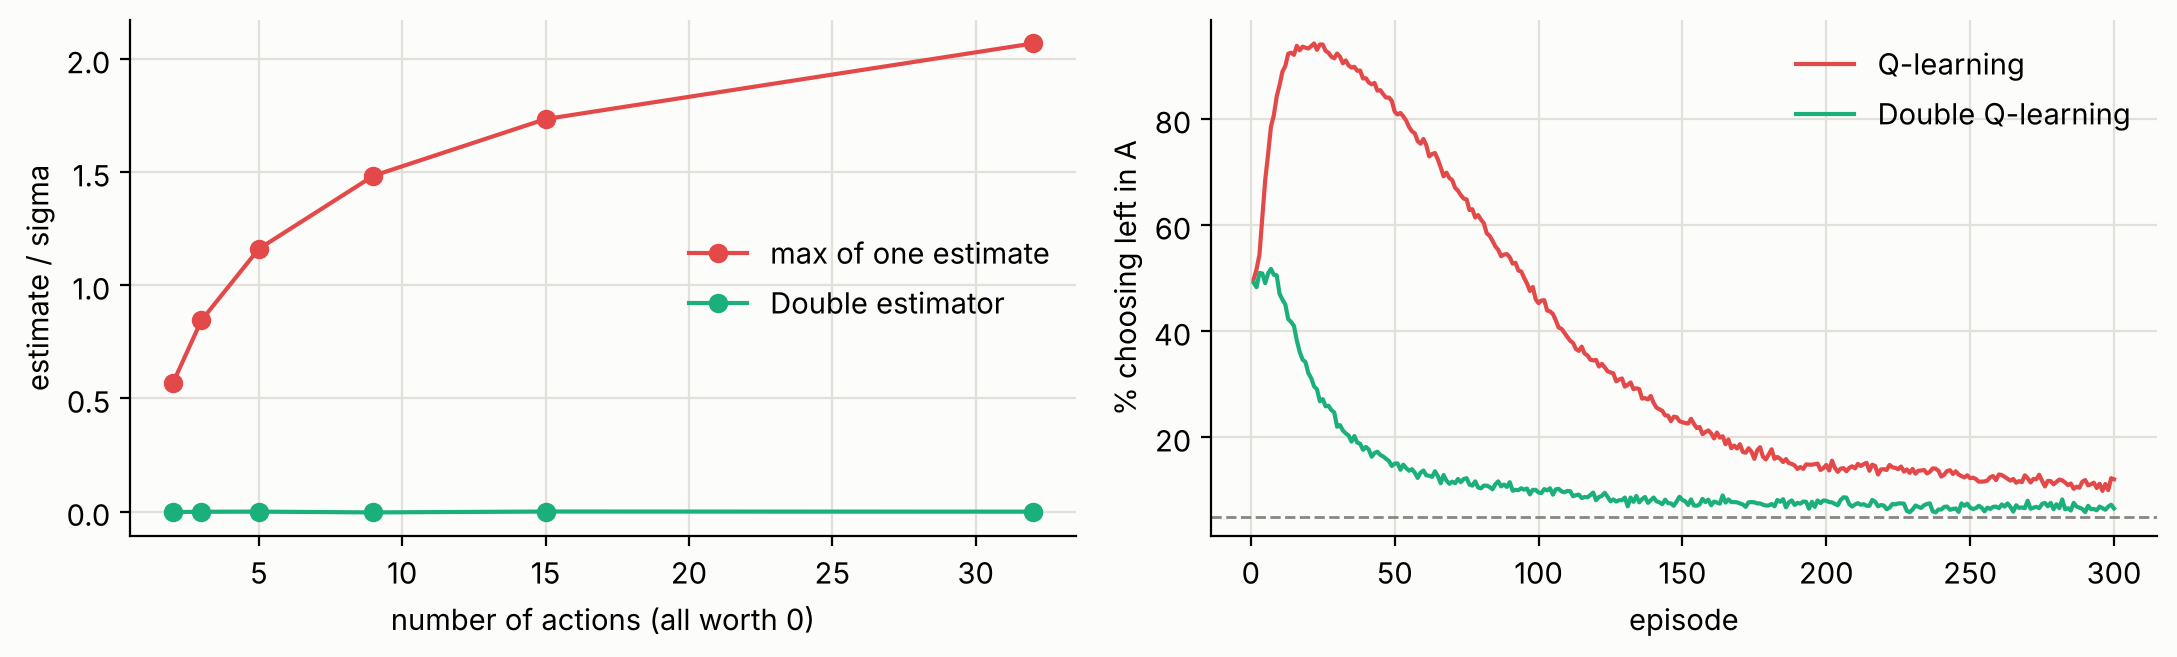

Q-learning peaks at 94 % 'left' (episode 22); Double Q-learning peaks at 52 %.
After 250 episodes: Q-learning 11.7 %, Double 6.8 % (optimal under eps=0.1: 5 %)


In [8]:
mb = maximization_bias()
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
axs[0].plot(ms, single, "o-", color=RED, label="max of one estimate"); axs[0].plot(ms, double, "o-", color=AQUA, label="Double estimator")
axs[0].set_xlabel("number of actions (all worth 0)"); axs[0].set_ylabel("estimate / sigma"); axs[0].legend()
ep = np.arange(1, 301)
axs[1].plot(ep, 100 * mb["q"], color=RED, label="Q-learning"); axs[1].plot(ep, 100 * mb["double"], color=AQUA, label="Double Q-learning")
axs[1].axhline(5, color=MUTED, ls="--", lw=1); axs[1].set_xlabel("episode"); axs[1].set_ylabel("% choosing left in A"); axs[1].legend()
plt.tight_layout(); plt.show()
print(f"Q-learning peaks at {100*mb['q'].max():.0f} % 'left' (episode {mb['q'].argmax()+1}); Double Q-learning peaks at {100*mb['double'].max():.0f} %.")
print(f"After 250 episodes: Q-learning {100*mb['q'][-50:].mean():.1f} %, Double {100*mb['double'][-50:].mean():.1f} % (optimal under eps=0.1: 5 %)")

In a deep network the fix is almost free — we already have two networks. **Double DQN** (van Hasselt, Guez & Silver
2016) chooses with the online net and values with the target net:

```python
# DQN target
q_next = tgt(s2).max(1).values
# Double DQN target: choose with the online net, value with the target net
a_star = net(s2).argmax(1, keepdim=True)
q_next = tgt(s2).gather(1, a_star).squeeze(1)
```

### 4.3 Dueling head
**Dueling networks** (Wang et al. 2016) split the last layer into a state value $V(s)$ and per-action advantages $A(s,a)$:
$Q = V + A - \text{mean}_a A$ (subtracting the mean makes the split identifiable). The motivation: in many states the action
barely matters, and $V$ gets a gradient from every transition regardless of which action was taken. It is implemented
in `QNet(dueling=True)` above.

### 4.4 Summary of the four extensions

| extension | changes | intended effect |
|---|---|---|
| Double DQN | which net *chooses* $a'$ in the target | remove max-bias |
| Dueling | network head | share value information across actions |
| n-step | the target (real rewards for $n$ steps) | faster credit assignment |
| PER | which transitions are sampled | spend updates where the TD error is large |

Whether each one *helps on your problem* is an empirical question — section 6 measures it.

## 5. The complete DQN

The evaluation routine runs the **greedy** policy (ε = 0) on fresh episodes and records, besides the return, the network's
own estimate $\max_a Q(s_0, a)$ and the realised discounted return from $s_0$ — the direct check of whether Q is
over- or under-estimating.

In [9]:
@torch.no_grad()
def evaluate(env_name, net, n, seed, gamma, horizon, repeat=1):
    '''Greedy rollout of n fresh episodes. Returns the undiscounted episode return (one normal
    episode, stops at a crash), the network's estimate max_a Q(s0,a), and the realised discounted
    Monte-Carlo return from s0 (rolled out to `horizon` physics steps so the time-out does not cut it).
    Quad extras: crash rate, hover error over the last second, success (no crash and error < 15 cm),
    and chatter = total |change in motor command| per second of flight.'''
    Env = ENVS[env_name]; ep_len = Env(n=1).max_steps
    E = Env(n=n, seed=seed, max_steps=horizon, repeat=repeat); o = E.reset()
    n_dec, h_dec = ep_len // repeat, horizon // repeat
    q0 = net(torch.as_tensor(o, dtype=torch.float32)).max(1).values.numpy()
    alive = np.ones(n, bool); ret = np.zeros(n); disc = np.zeros(n); g = 1.0
    err_tail, du_sum, crashed = [], np.zeros(n), np.zeros(n, bool)
    for t in range(h_dec):
        a = net(torch.as_tensor(o, dtype=torch.float32)).argmax(1).numpy()
        o, r, term, trunc, _ = E.step(a)
        r = np.where(alive, r, 0.0)
        disc += g * r; g *= gamma
        if t < n_dec:
            ret += r
            crashed |= term & alive
            if env_name == "quad":
                du_sum += np.where(alive, E.info["du"], 0)
                if t >= n_dec - 50 // repeat: err_tail.append(np.where(alive & ~term, E.info["err"], np.nan))
        alive &= ~term
    out = dict(ret=ret.mean(), q0=q0.mean(), mc=disc.mean(), crash=crashed.mean())
    if env_name == "quad":
        et = np.array(err_tail); ok = ~np.isnan(et)
        err = np.where(ok.any(0), np.where(ok, et, 0).sum(0) / np.maximum(ok.sum(0), 1), np.inf)
        fin = np.isfinite(err)
        out.update(err=err[fin].mean() if fin.any() else np.nan, success=np.mean(~crashed & (err < 0.15)),
                   chatter=du_sum.mean() / (ep_len * Env.DT))
    return out

The training loop. Read the update block carefully — it is the whole algorithm in about 20 lines.

Three bugs that are easy to write and silently cost you most of the performance:

```python
# WRONG: treating a time-out as terminal - the agent learns that 'the world ends at step 500'
done = term | trunc
# RIGHT: only true terminations stop the bootstrap; time-outs bootstrap from the final observation
done = term

# WRONG: gradient flows into the target (and through max) - the target chases the prediction
y = r + gamma * tgt(s2).max(1).values
# RIGHT
with torch.no_grad(): y = r + gamma * (1 - done) * tgt(s2).max(1).values

# WRONG: exploring during evaluation, then reporting the noisy return as 'performance'
# RIGHT: evaluate the greedy policy on separate seeded episodes
```

In [10]:
BASE = {
  "cartpole": dict(n_envs=4, total=60_000, buffer=50_000, batch=128, lr=1e-3, gamma=0.99,
                   target_update=100, learning_starts=1_000, eps_start=1.0, eps_end=0.02,
                   eps_frac=0.25, train_every=1, grad_steps=1, double=False, dueling=False,
                   nstep=1, per_alpha=0.0, per_beta0=0.4, huber=True, hidden=(64, 64),
                   grad_clip=10.0, eval_every=2_500, eval_envs=10, mc_horizon=1000, repeat=1),
  "quad": dict(n_envs=8, total=400_000, buffer=100_000, batch=128, lr=5e-4, gamma=0.99,
               target_update=500, learning_starts=2_000, eps_start=1.0, eps_end=0.02,
               eps_frac=0.20, train_every=1, grad_steps=1, double=False, dueling=False,
               nstep=1, per_alpha=0.0, per_beta0=0.4, huber=True, hidden=(128, 128),
               grad_clip=10.0, eval_every=20_000, eval_envs=16, mc_horizon=700, repeat=2),
}
RAINBOWISH = dict(double=True, dueling=True, nstep=3, per_alpha=0.6)

def make_cfg(env, **kw):
    c = dict(BASE[env]); c.update(kw); return c

def train_dqn(env_name, cfg, seed=0, verbose=False, keep_net=False):
    '''DQN (Mnih et al. 2015) with optional Double / Dueling / n-step / prioritised replay.
    Returns a log dict: eval curve + per-update diagnostics (loss, |TD|, mean max-Q, grad norm).'''
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    c = cfg; Env = ENVS[env_name]
    env = Env(n=c["n_envs"], seed=seed, repeat=c["repeat"])
    net = QNet(Env.obs_dim, Env.n_actions, c["hidden"], c["dueling"])
    tgt = copy.deepcopy(net); opt = torch.optim.Adam(net.parameters(), lr=c["lr"])
    rb = Replay(c["buffer"], Env.obs_dim, rng, c["per_alpha"])
    ns = NStep(c["n_envs"], c["nstep"], c["gamma"])
    o = env.reset(); steps = updates = 0; t0 = time.time()
    L = dict(steps=[], ret=[], q0=[], mc=[], crash=[], err=[], success=[], chatter=[],
             u_step=[], loss=[], td=[], qmean=[], gnorm=[], eps=[], act_hist=np.zeros(Env.n_actions))
    acc = dict(loss=0., td=0., q=0., g=0., k=0)
    next_eval = 0
    while steps < c["total"]:
        if steps >= next_eval:
            ev = evaluate(env_name, net, c["eval_envs"], 10_000 + seed, c["gamma"], c["mc_horizon"], c["repeat"])
            L["steps"].append(steps)
            for k in ("ret", "q0", "mc", "crash", "err", "success", "chatter"):
                L[k].append(ev.get(k, np.nan))
            if verbose: print(f"{steps:7d}  ret {ev['ret']:7.1f}  Q0 {ev['q0']:7.2f}  MC {ev['mc']:7.2f}")
            next_eval += c["eval_every"]
        eps = max(c["eps_end"], c["eps_start"] - (c["eps_start"] - c["eps_end"]) * steps / (c["eps_frac"] * c["total"]))
        with torch.no_grad():
            greedy = net(torch.as_tensor(o, dtype=torch.float32)).argmax(1).numpy()
        rand = rng.random(c["n_envs"]) < eps
        a = np.where(rand, rng.integers(0, Env.n_actions, c["n_envs"]), greedy)
        L["act_hist"] += np.bincount(greedy, minlength=Env.n_actions)
        no, r, term, trunc, final = env.step(a)
        tr = ns.push(o, a, r, no, term, trunc, final)
        if tr is not None: rb.add(*tr)
        o = no; steps += c["n_envs"] * c["repeat"]; vsteps = steps // (c["n_envs"] * c["repeat"])
        if steps >= c["learning_starts"] and vsteps % c["train_every"] == 0:
            for _ in range(c["grad_steps"]):
                beta = c["per_beta0"] + (1 - c["per_beta0"]) * min(1.0, steps / c["total"])
                idx, (bo, ba, br, bno, bd, bg), w = rb.sample(c["batch"], beta)
                bo, bno = torch.as_tensor(bo), torch.as_tensor(bno)
                ba = torch.as_tensor(ba); br, bd, bg = map(torch.as_tensor, (br, bd, bg))
                qall = net(bo); q = qall.gather(1, ba[:, None]).squeeze(1)
                with torch.no_grad():
                    if c["double"]:
                        an = net(bno).argmax(1, keepdim=True); qn = tgt(bno).gather(1, an).squeeze(1)
                    else:
                        qn = tgt(bno).max(1).values
                    y = br + bg * (1 - bd) * qn
                td = y - q
                el = F.smooth_l1_loss(q, y, reduction="none") if c["huber"] else 0.5 * td**2
                loss = (torch.as_tensor(w) * el).mean()
                opt.zero_grad(); loss.backward()
                gn = nn.utils.clip_grad_norm_(net.parameters(), c["grad_clip"])
                opt.step(); updates += 1
                if c["per_alpha"] > 0: rb.update(idx, td.detach().numpy())
                if updates % c["target_update"] == 0: tgt.load_state_dict(net.state_dict())
                acc["loss"] += loss.item(); acc["td"] += td.abs().mean().item()
                acc["q"] += qall.max(1).values.mean().item(); acc["g"] += gn.item(); acc["k"] += 1
                if acc["k"] == 100:
                    L["u_step"].append(steps)
                    for k, kk in (("loss", "loss"), ("td", "td"), ("qmean", "q"), ("gnorm", "g")):
                        L[k].append(acc[kk] / 100)
                    L["eps"].append(eps); acc = dict(loss=0., td=0., q=0., g=0., k=0)
    ev = evaluate(env_name, net, c["eval_envs"], 10_000 + seed, c["gamma"], c["mc_horizon"], c["repeat"])
    L["steps"].append(steps)
    for k in ("ret", "q0", "mc", "crash", "err", "success", "chatter"): L[k].append(ev.get(k, np.nan))
    L["time"] = time.time() - t0; L["updates"] = updates
    L = {k: (np.asarray(v) if isinstance(v, list) else v) for k, v in L.items()}
    if keep_net: L["state_dict"] = {k: v.clone() for k, v in net.state_dict().items()}
    return L

def final_score(L, k="ret", last=3):
    '''Mean of the last `last` evaluations - smooths out one lucky or unlucky evaluation.'''
    return float(np.nanmean(L[k][-last:]))

## 6. Experiments on CartPole

Ten variants, three seeds each, 60 k environment steps per run. The baseline is **vanilla DQN**: replay buffer of 50 k,
target network copied every 100 updates, Huber loss, ε decayed from 1 to 0.02 over the first 25 % of training, Adam
lr 1e-3, 64×64 ReLU. Then:

* **add one extension at a time** (Double, dueling, 3-step, PER) and **all four together**;
* **remove a stabiliser**: no target network (copied every update), target copied too rarely (every 1000), a replay
  buffer of only 1 k transitions, and MSE instead of Huber.

The runs go to two worker processes (`fork` start method; on Windows/macOS set `POOL = None` to run sequentially).

In [11]:
RB = RAINBOWISH
CP = {"vanilla": {}, "+double": dict(double=True), "+dueling": dict(dueling=True), "+3-step": dict(nstep=3),
      "+PER": dict(per_alpha=0.6), "all four": RB,
      "no target net": dict(target_update=1), "target every 1000": dict(target_update=1000),
      "buffer 1k": dict(buffer=1000), "MSE loss": dict(huber=False)}
QD = {"DQN 50 Hz": dict(repeat=1), "DQN 25 Hz": dict(repeat=2), "DQN 12.5 Hz": dict(repeat=4),
      "DQN 25 Hz, all four": dict(repeat=2, **RB)}

def run_job(job):
    torch.set_num_threads(1); kind, name, kw, seed = job
    if kind == "ppo": L = train_ppo_quad(seed)
    else: L = train_dqn(kind, make_cfg(kind, **kw), seed, keep_net=(seed == 0))
    return (kind, name, seed), L

def run_all(jobs):
    out = {}; t0 = time.time()
    POOL = mp.get_context("fork") if sys.platform.startswith("linux") else None
    if POOL is None:
        for j in jobs: k, L = run_job(j); out[k] = L
    else:
        with POOL.Pool(2) as p:
            for k, L in p.imap_unordered(run_job, jobs): out[k] = L
    print(f"{len(jobs)} runs in {time.time() - t0:.0f} s")
    return out

CPR = run_all([("cartpole", n, kw, s) for n, kw in CP.items() for s in SEEDS])

30 runs in 475 s


In [12]:
def grp(D, kind, name): return [D[(kind, name, s)] for s in SEEDS]
print(f"{'variant':20s} {'final return':>13s} {'per seed':>24s} {'solved':>7s} {'max of mean-max-Q':>18s}")
for name in CP:
    G = grp(CPR, "cartpole", name); fs = [final_score(L) for L in G]
    print(f"{name:20s} {np.mean(fs):13.1f} {str([round(x) for x in fs]):>24s} {sum(x >= 475 for x in fs):4d}/{len(SEEDS)} {max(L['qmean'].max() for L in G):18.3g}")

variant               final return                 per seed  solved  max of mean-max-Q
vanilla                      322.0          [463, 375, 128]    0/3               74.6
+double                      287.1          [500, 151, 211]    1/3                 76
+dueling                      80.9           [110, 106, 27]    0/3               71.5
+3-step                      379.9          [500, 500, 140]    2/3                128
+PER                         401.9          [309, 397, 500]    1/3               64.1
all four                     499.9          [500, 500, 500]    3/3               90.9
no target net                  9.4              [10, 9, 10]    0/3           2.62e+07
target every 1000            146.0          [156, 163, 118]    0/3               14.6
buffer 1k                    119.2          [114, 108, 135]    0/3                 81
MSE loss                     374.0          [321, 351, 449]    0/3               74.6


### 6.1 The stabilisers

* **No target network → divergence.** Q climbs to ~2.6e+07 while the return never leaves
  ~9. Every update moves the target it is regressing onto; with bootstrapping and function approximation that feedback
  loop runs away. This is the deadly triad, live.
* **Target copied every 1000 updates → too slow.** Nothing diverges, but value information moves only one bootstrap step per
  copy, so Q crawls up in visible stairs (to only 14.6 by the end, against a ceiling of
  $1/(1-\gamma) = 100$) and the policy stalls at 146.
* **Replay of only 1 k transitions → stuck near 119.** The buffer holds ~4 short episodes;
  the network overfits the most recent behaviour and forgets what it knew.
* **MSE instead of Huber: no measurable difference here** (374 vs 322,
  inside seed noise). Huber matters when rewards are large or unclipped; CartPole's +1 rewards keep TD errors small. Keep
  it as a default, but do not credit it with this result.

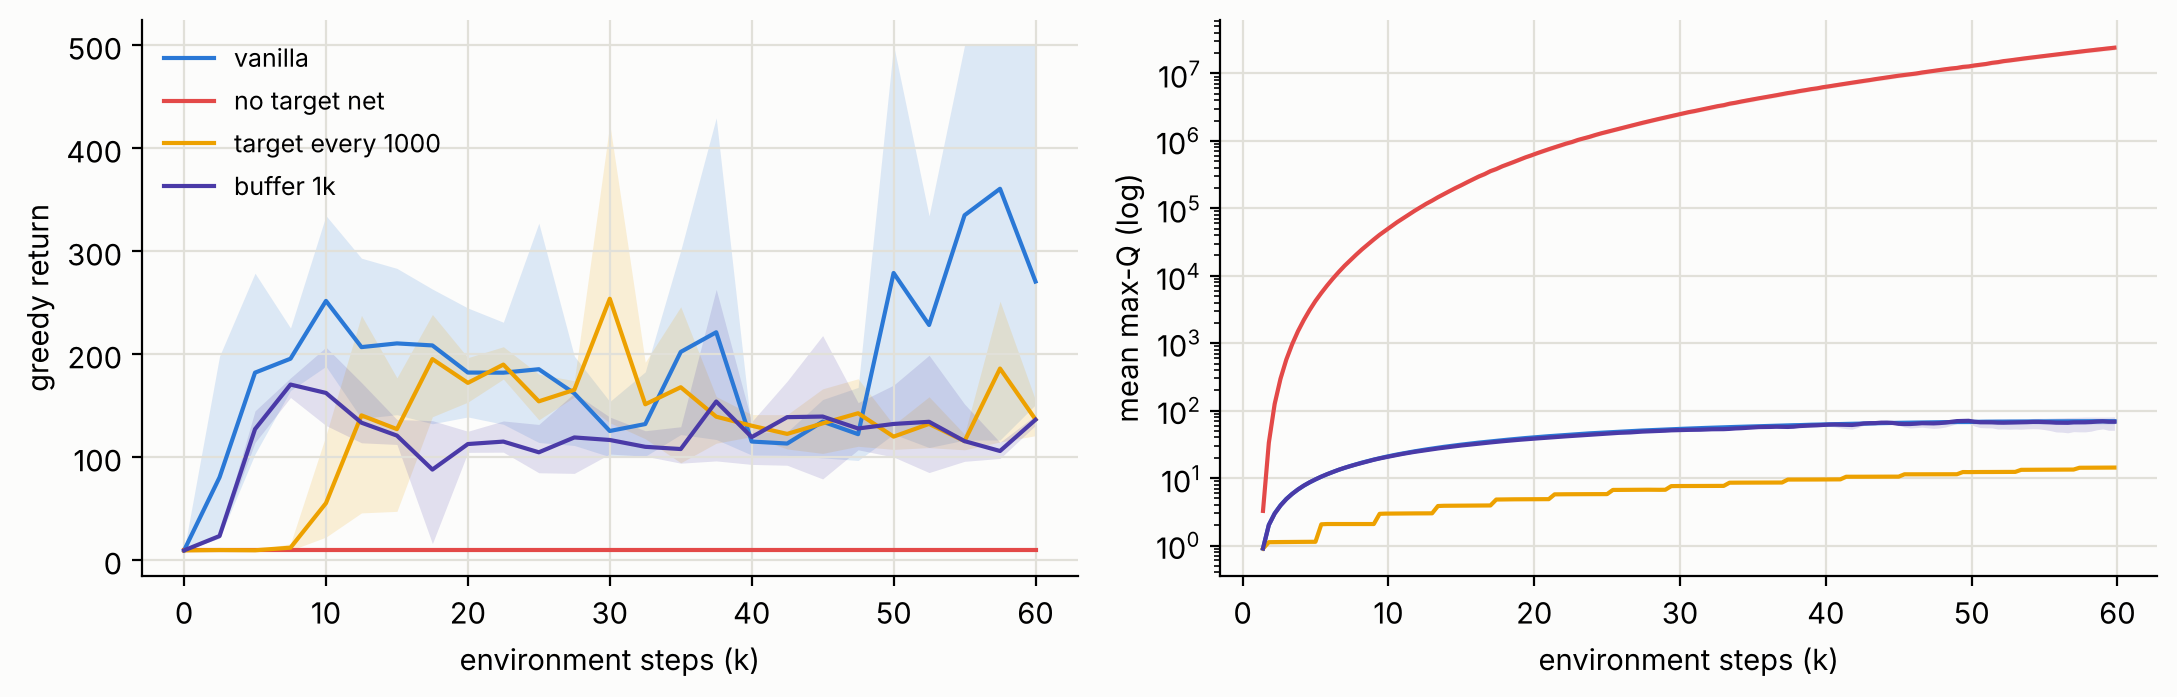

In [13]:
def band(ax, D, kind, name, key="ret", color=BLUE, label=None, x="steps", log=False):
    G = grp(D, kind, name); X = G[0][x] / 1e3; Y = np.array([L[key] for L in G])
    if log: Y = np.maximum(Y, 1e-3); m = np.exp(np.log(Y).mean(0))
    else: m = Y.mean(0)
    ax.fill_between(X, Y.min(0), Y.max(0), color=color, alpha=0.15, lw=0); ax.plot(X, m, color=color, label=label or name)

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for n, c in (("vanilla", BLUE), ("no target net", RED), ("target every 1000", YELLOW), ("buffer 1k", VIOLET)):
    band(axs[0], CPR, "cartpole", n, "ret", c); band(axs[1], CPR, "cartpole", n, "qmean", c, x="u_step", log=True)
axs[0].set_ylabel("greedy return"); axs[1].set_ylabel("mean max-Q (log)"); axs[1].set_yscale("log")
for a in axs: a.set_xlabel("environment steps (k)")
axs[0].legend(fontsize=9); plt.tight_layout(); plt.show()

### 6.2 The four extensions

| variant | final return (3 seeds) | seeds solved |
|---|---|---|
| vanilla | 322 | 0/3 |
| + Double | 287 | 1/3 |
| + dueling | 81 | 0/3 |
| + 3-step | 380 | 2/3 |
| + PER | 402 | 1/3 |
| **all four** | **500** | **3/3** |

What the table says — honestly:

* **All four together solve CartPole on every seed**, reaching 475 by 40000–42500 steps. Vanilla solves none.
* **n-step returns are the largest single contributor** (2/3 seeds). CartPole's only signal is "you failed", and 3-step
  targets carry that news back three times faster.
* **PER helps a little and Double helps on one seed**; with 3 seeds neither is clearly separated from vanilla's spread.
* **Dueling on its own made things worse** (81). With 2 actions there is little to share
  between them, and the extra head changes the optimisation. It does no harm inside the full combination. *This is the
  lesson of the PPO deep dive again: ablate before you believe.*
* **Did Double DQN help by removing overestimation?** Not here. Compare the network's $\max_a Q(s_0,a)$ with the realised
  discounted return in the cell below: on CartPole Q sits *below* the realised return throughout training, for vanilla and
  Double alike — the value is still propagating, so there is no overestimation to remove. Double DQN's benefit in the Atari
  results came from large action sets and noisy rewards; ours has two actions and deterministic rewards.

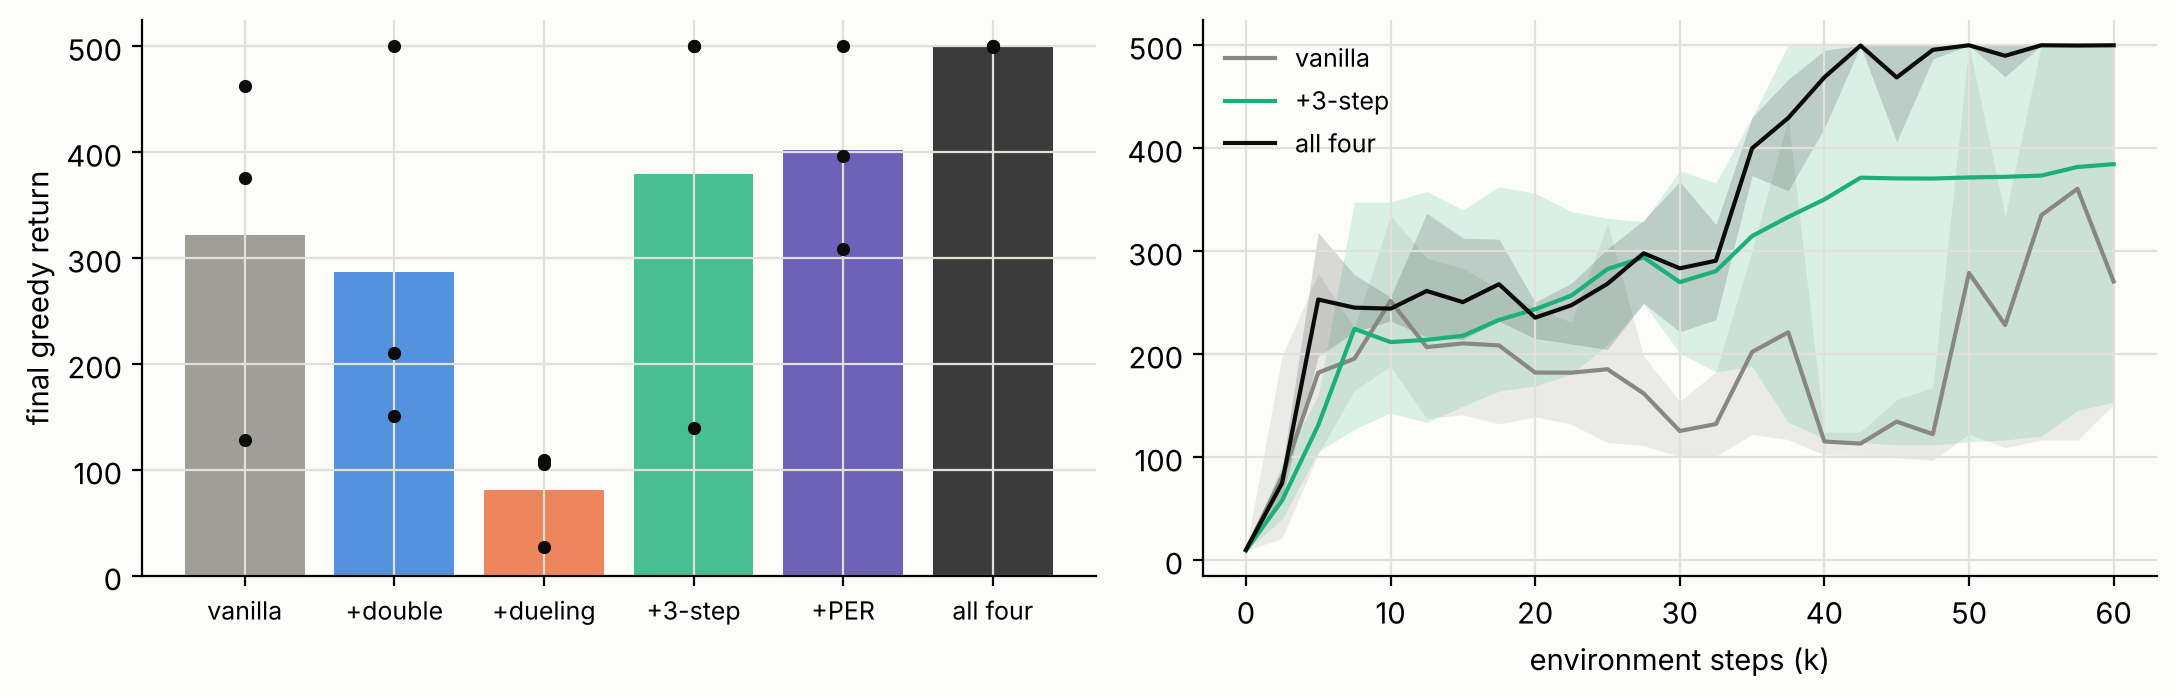

Q-estimate minus realised discounted return at s0, averaged over evaluations after 5 k steps:
  vanilla    [-22.3 -27.8 -26.1]  (negative = underestimate)
  +double    [-33.  -21.  -15.1]  (negative = underestimate)
  all four   [-12.6 -13.9 -14.3]  (negative = underestimate)


In [14]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for n, c in zip(["vanilla", "+double", "+dueling", "+3-step", "+PER", "all four"], [MUTED, BLUE, ORANGE, AQUA, VIOLET, INK]):
    fs = [final_score(L) for L in grp(CPR, "cartpole", n)]
    axs[0].bar(n, np.mean(fs), color=c, alpha=0.8); axs[0].scatter([n] * len(fs), fs, color=INK, s=14, zorder=3)
axs[0].set_ylabel("final greedy return"); axs[0].tick_params(axis="x", labelsize=9)
for n, c in (("vanilla", MUTED), ("+3-step", AQUA), ("all four", INK)): band(axs[1], CPR, "cartpole", n, "ret", c)
axs[1].set_xlabel("environment steps (k)"); axs[1].legend(fontsize=9); plt.tight_layout(); plt.show()

print("Q-estimate minus realised discounted return at s0, averaged over evaluations after 5 k steps:")
for n in ("vanilla", "+double", "all four"):
    b = [np.mean(L["q0"][L["steps"] >= 5000] - L["mc"][L["steps"] >= 5000]) for L in grp(CPR, "cartpole", n)]
    print(f"  {n:10s}", np.round(b, 1), " (negative = underestimate)")

## 7. The quadrotor: DQN on a continuous-control task, and DQN vs PPO

### 7.1 Two design decisions PPO never asked us to make

1. **The action menu.** DQN can only choose from a finite list, so the menu sets the best precision it can reach and how
   much it must switch. We use 15 actions (§1).
2. **The decision rate.** The environment runs at 50 Hz, but DQN may hold each action for `repeat` physics steps.
   Holding longer makes each decision matter more — the gap between the Q-values of good and bad actions grows with the hold
   time (Tallec, Blier & Ollivier 2019 call this the *action gap*) — and cuts the number of network updates. Deciding more
   often allows finer corrections.

We train vanilla DQN at 50, 25 and 12.5 Hz, the 25 Hz version with all four extensions, and the continuous PPO from the
PPO deep dive (16 envs × 256 steps, 10 epochs, clip 0.2, GAE λ 0.95, 800 k steps). Step counts are in **physics steps**
(20 ms of simulated flight each) for every method, so the comparison is per second of experience.

In [15]:
class RunningNorm:
    def __init__(self, d): self.m = np.zeros(d); self.v = np.ones(d); self.n = 1e-4
    def update(self, x):
        bm, bv, bn = x.mean(0), x.var(0), len(x); d = bm - self.m; tot = self.n + bn
        self.m = self.m + d * bn / tot
        self.v = (self.v * self.n + bv * bn + d**2 * self.n * bn / tot) / tot; self.n = tot
    def __call__(self, x): return np.clip((x - self.m) / np.sqrt(self.v + 1e-8), -10, 10)

def _mlp(i, o, gain):
    net = nn.Sequential(nn.Linear(i, 64), nn.Tanh(), nn.Linear(64, 64), nn.Tanh(), nn.Linear(64, o))
    for m in net:
        if isinstance(m, nn.Linear): nn.init.orthogonal_(m.weight, math.sqrt(2)); nn.init.zeros_(m.bias)
    nn.init.orthogonal_(net[-1].weight, gain); return net

def train_ppo_quad(seed=0, total=800_000, n_envs=16, T=256, epochs=10, n_mb=4, lr=3e-4,
                   gamma=0.99, lam=0.95, clip=0.2, eval_every=40_000, eval_envs=16):
    '''Compact PPO-clip for the continuous-action quad, same settings as the PPO deep dive.'''
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    env = PlanarQuad(n=n_envs, seed=seed); D = PlanarQuad.obs_dim
    pi, vf = _mlp(D, 2, 0.01), _mlp(D, 1, 1.0); logstd = nn.Parameter(torch.full((2,), -0.5))
    opt = torch.optim.Adam(list(pi.parameters()) + list(vf.parameters()) + [logstd], lr=lr, eps=1e-5)
    on, ret_rms, ret_acc = RunningNorm(D), RunningNorm(1), np.zeros(n_envs)
    o = env.reset(); steps = 0; t0 = time.time(); n_up = total // (n_envs * T)
    L = dict(steps=[], ret=[], crash=[], err=[], success=[], chatter=[])
    def do_eval():
        E = PlanarQuad(n=eval_envs, seed=10_000 + seed); ob = E.reset(); alive = np.ones(eval_envs, bool)
        ret = np.zeros(eval_envs); du = np.zeros(eval_envs); tail = []; crashed = np.zeros(eval_envs, bool)
        for t in range(E.max_steps):
            with torch.no_grad(): a = pi(torch.as_tensor(on(ob), dtype=torch.float32)).numpy()
            ob, r, term, trunc, _ = E.step(np.clip(a, -1, 1))
            ret += np.where(alive, r, 0); du += np.where(alive, E.info["du"], 0)
            if t >= E.max_steps - 50: tail.append(np.where(alive, E.info["err"], np.nan))
            crashed |= term & alive; alive &= ~term
        et = np.array(tail); ok = ~np.isnan(et)
        err = np.where(ok.any(0), np.where(ok, et, 0).sum(0) / np.maximum(ok.sum(0), 1), np.inf)
        fin = np.isfinite(err)
        L["steps"].append(steps); L["ret"].append(ret.mean()); L["crash"].append(crashed.mean())
        L["err"].append(err[fin].mean() if fin.any() else np.nan); L["success"].append(np.mean(~crashed & (err < 0.15)))
        L["chatter"].append(du.mean() / (E.max_steps * E.DT))
    next_eval = 0
    for u in range(n_up):
        if steps >= next_eval: do_eval(); next_eval += eval_every
        for gp in opt.param_groups: gp["lr"] = lr * (1 - u / n_up)
        B = dict(o=np.zeros((T, n_envs, D)), a=np.zeros((T, n_envs, 2)), lp=np.zeros((T, n_envs)),
                 r=np.zeros((T, n_envs)), v=np.zeros((T, n_envs)), d=np.zeros((T, n_envs)),
                 vb=np.zeros((T, n_envs)))
        for t in range(T):
            on.update(o); x = torch.as_tensor(on(o), dtype=torch.float32)
            with torch.no_grad():
                mu = pi(x); dist = torch.distributions.Normal(mu, logstd.exp())
                a = dist.sample(); lp = dist.log_prob(a).sum(1); v = vf(x).squeeze(1)
            no, r, term, trunc, final = env.step(a.numpy())
            ret_acc = ret_acc * gamma + r; ret_rms.update(ret_acc[:, None]); ret_acc[term | trunc] = 0
            rs = r / math.sqrt(ret_rms.v[0] + 1e-8)
            vb = np.zeros(n_envs)
            if trunc.any():
                with torch.no_grad():
                    vb[trunc] = vf(torch.as_tensor(on(final[trunc]), dtype=torch.float32)).squeeze(1).numpy()
            B["o"][t], B["a"][t], B["lp"][t], B["r"][t], B["v"][t] = on(o), a.numpy(), lp.numpy(), rs + gamma * vb, v.numpy()
            B["d"][t] = term | trunc; o = no; steps += n_envs
        with torch.no_grad(): vlast = vf(torch.as_tensor(on(o), dtype=torch.float32)).squeeze(1).numpy()
        adv = np.zeros((T, n_envs)); gae = 0
        for t in reversed(range(T)):
            vn = vlast if t == T - 1 else B["v"][t + 1]
            delta = B["r"][t] + gamma * vn * (1 - B["d"][t]) - B["v"][t]
            gae = delta + gamma * lam * (1 - B["d"][t]) * gae; adv[t] = gae
        rets = adv + B["v"]
        fo, fa, flp = (torch.as_tensor(B[k].reshape(T * n_envs, -1), dtype=torch.float32) for k in ("o", "a", "lp"))
        flp = flp.squeeze(1); fadv = torch.as_tensor(adv.ravel(), dtype=torch.float32)
        fret = torch.as_tensor(rets.ravel(), dtype=torch.float32); N = T * n_envs; mb = N // n_mb
        for _ in range(epochs):
            perm = rng.permutation(N)
            for s in range(0, N, mb):
                j = perm[s:s + mb]; A = fadv[j]; A = (A - A.mean()) / (A.std() + 1e-8)
                dist = torch.distributions.Normal(pi(fo[j]), logstd.exp())
                ratio = (dist.log_prob(fa[j]).sum(1) - flp[j]).exp()
                lpi = -torch.min(ratio * A, ratio.clamp(1 - clip, 1 + clip) * A).mean()
                lv = 0.5 * ((vf(fo[j]).squeeze(1) - fret[j]) ** 2).mean()
                opt.zero_grad(); (lpi + 0.5 * lv).backward()
                nn.utils.clip_grad_norm_(list(pi.parameters()) + list(vf.parameters()), 0.5); opt.step()
    do_eval(); L = {k: np.asarray(v) for k, v in L.items()}; L["time"] = time.time() - t0
    L["pi_state"] = {k: v.clone() for k, v in pi.state_dict().items()}; L["obs_norm"] = (on.m.copy(), on.v.copy())
    return L

In [16]:
QDR = run_all([("quad", n, kw, s) for n, kw in QD.items() for s in SEEDS] + [("ppo", "PPO", None, s) for s in SEEDS])

def reach(L, thr=190):
    i = np.flatnonzero(L["ret"] >= thr); return L["steps"][i[0]] if len(i) else np.nan
print(f"{'method':22s} {'return':>7s} {'success':>8s} {'crash':>6s} {'hover err':>10s} {'chatter /s':>11s} {'steps to 190':>13s} {'wall s':>7s}")
for kind, name in [("quad", n) for n in QD] + [("ppo", "PPO")]:
    G = grp(QDR, kind, name)
    row = [np.mean([final_score(L, k) for L in G]) for k in ("ret", "success", "crash", "err", "chatter")]
    print(f"{name:22s} {row[0]:7.1f} {row[1]:8.0%} {row[2]:6.0%} {100*row[3]:8.2f} cm {row[4]:11.2f} "
          f"{np.mean([reach(L) for L in G])/1e3:10.0f} k {np.mean([L['time'] for L in G]):7.0f}")

15 runs in 479 s
method                  return  success  crash  hover err  chatter /s  steps to 190  wall s
DQN 50 Hz                218.1     100%     0%     1.58 cm       15.06        113 k     104
DQN 25 Hz                218.1     100%     0%     1.98 cm        9.73        120 k      54
DQN 12.5 Hz              208.9     100%     0%     4.01 cm        5.94        120 k      29
DQN 25 Hz, all four      215.9     100%     0%     1.98 cm       11.42         67 k      79
PPO                      215.0     100%     0%     0.98 cm        1.08        150 k      51


### 7.2 Reading the table

* **Every DQN variant learns to hover with 100 % success** and a hover error of 1.6–4 cm; the continuous PD reference
  gets a return of 219.
* **The decision rate is a three-way trade-off.** 50 Hz is the most precise (1.6 cm) but
  chatters most (15.1 per s) and does 49 k updates
  (~99 s). 12.5 Hz chatters least and trains in 27 s but
  hovers 4.0 cm off. 25 Hz is the middle we use for the comparison.
* **The four extensions buy sample efficiency, not final quality**: return 190 at
  67 k physics steps instead of 120 k;
  both end at the same return.
* **DQN vs PPO.** DQN + all four reaches 190 in roughly **half the experience** PPO needs
  (150 k) — replay reuses every transition many times, PPO throws each batch away
  after 10 epochs. But PPO's commands are smooth: chatter 1.08 per s against
  11.4 for DQN, about **11×** less,
  and a tighter hover (1.0 cm). Wall-clock time is similar (~53 s vs ~79 s):
  DQN is cheaper per *sample*, PPO cheaper per *second of compute* at this scale.

The chatter is visible in one flight from the same start:

DQN + all four (25 Hz, 15 actions)  : total |change in command| per second = 9.23
PPO (50 Hz, continuous)             : total |change in command| per second = 0.88


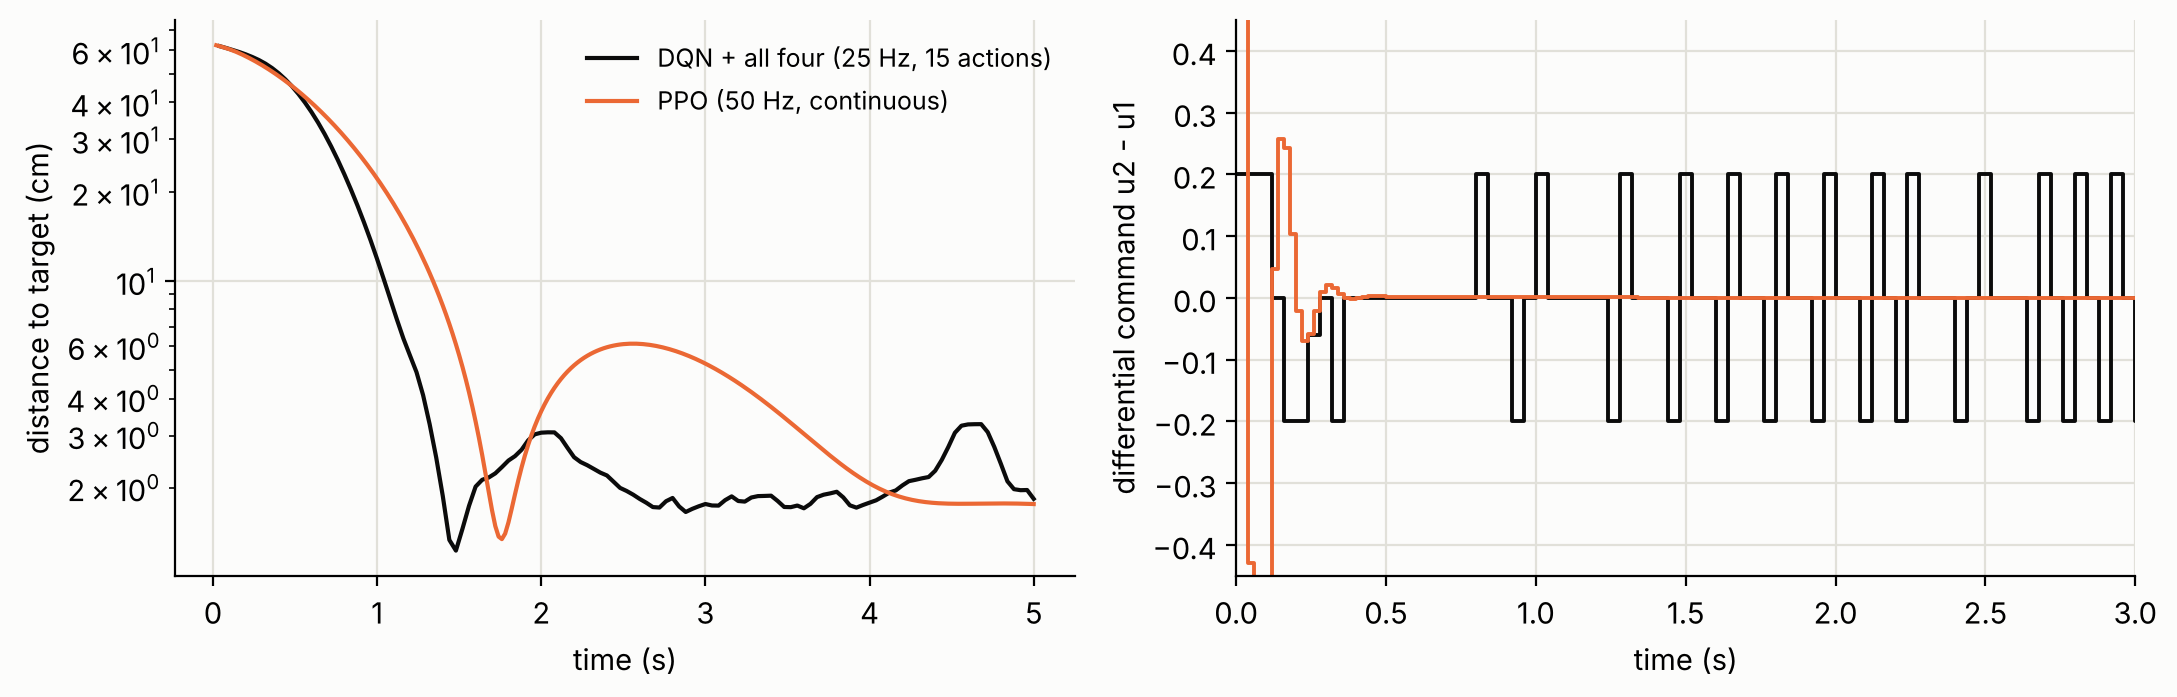

In [17]:
net = QNet(9, 15, (128, 128), dueling=True); net.load_state_dict(QDR[("quad", "DQN 25 Hz, all four", 0)]["state_dict"])
pi = _mlp(9, 2, 0.01); pi.load_state_dict(QDR[("ppo", "PPO", 0)]["pi_state"]); m_, v_ = QDR[("ppo", "PPO", 0)]["obs_norm"]

def fly(kind, seed=4242):
    E = PlanarQuad(n=1, seed=seed, repeat=2 if kind == "dqn" else 1); o = E.reset(); U, T, Er = [], [], []; t = 0.0
    while t < 5.0 - 1e-9:
        with torch.no_grad():
            if kind == "dqn": u = PlanarQuad.ACTIONS[net(torch.as_tensor(o, dtype=torch.float32)).argmax(1).numpy()]
            else: u = np.clip(pi(torch.as_tensor(np.clip((o - m_) / np.sqrt(v_ + 1e-8), -10, 10), dtype=torch.float32)).numpy(), -1, 1)
        for k in range(E.repeat): U.append(u[0].copy()); T.append(t + k * E.DT)
        o, r, term, trunc, _ = E.step(u); t += E.repeat * E.DT; Er.append((t, E.info["err"][0]))
    return np.array(T), np.array(U), np.array(Er)

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for kind, c, lab in (("dqn", INK, "DQN + all four (25 Hz, 15 actions)"), ("ppo", ORANGE, "PPO (50 Hz, continuous)")):
    T, U, Er = fly(kind)
    axs[0].semilogy(Er[:, 0], 100 * Er[:, 1], color=c, label=lab)
    axs[1].step(T, U[:, 1] - U[:, 0], where="post", color=c, lw=1.4, label=lab)
    print(f"{lab:36s}: total |change in command| per second = {np.abs(np.diff(U, axis=0)).sum() / 5.0:.2f}")
axs[0].set_xlabel("time (s)"); axs[0].set_ylabel("distance to target (cm)"); axs[0].legend(fontsize=9)
axs[1].set_xlim(0, 3); axs[1].set_ylim(-0.45, 0.45); axs[1].set_xlabel("time (s)"); axs[1].set_ylabel("differential command u2 - u1")
plt.tight_layout(); plt.show()

DQN reaches the target as fast as PPO, then **holds it by switching** between neighbouring menu entries — a bang-bang
controller it discovered for itself. On a real vehicle that switching is motor wear, audible noise and excitation of
structural modes. The usual remedies are a finer menu (more actions → more max-bias and slower learning), a penalty on
$|\Delta u|$ in the reward (already present here, weight 0.05, and evidently not enough), a low-pass filter on the
command, or a continuous-action method (PPO, SAC, TD3).

## 8. Diagnostics: reading a DQN run

Return alone tells you *that* a run failed, not *why*. Log these four signals every ~100 updates (the training loop above
does) and you can usually name the failure:

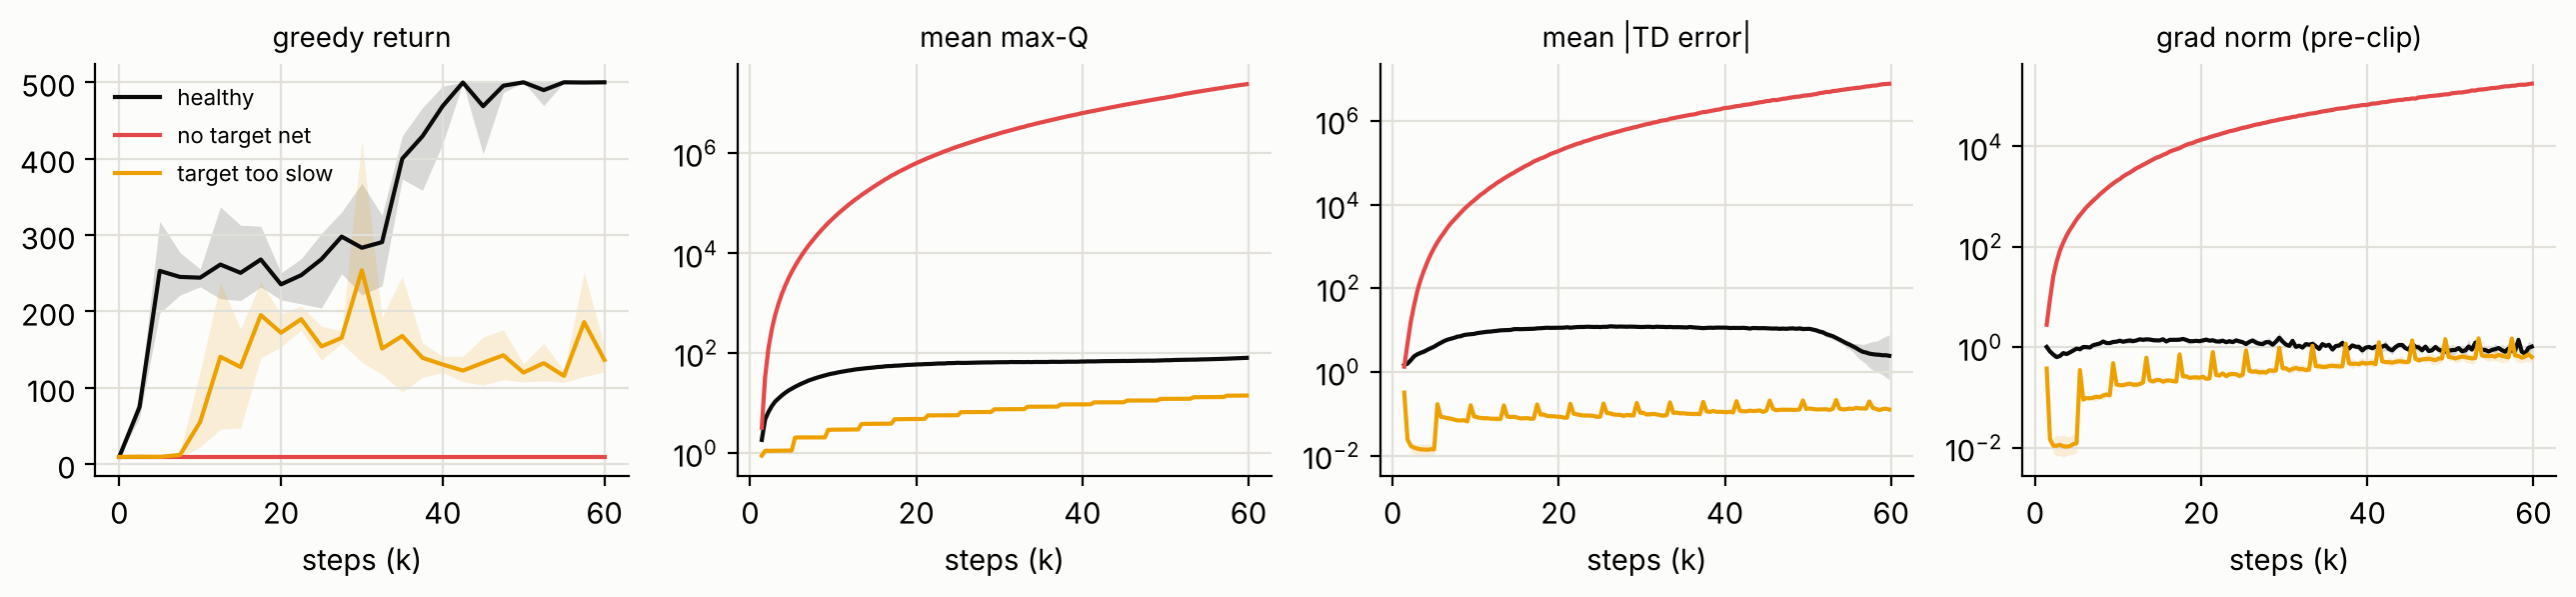

In [18]:
fig, axs = plt.subplots(1, 4, figsize=(13, 3.1))
for n, c, lab in (("all four", INK, "healthy"), ("no target net", RED, "no target net"), ("target every 1000", YELLOW, "target too slow")):
    band(axs[0], CPR, "cartpole", n, "ret", c, lab)
    for ax, k in zip(axs[1:], ("qmean", "td", "gnorm")): band(ax, CPR, "cartpole", n, k, c, lab, x="u_step", log=True)
for ax, t in zip(axs, ["greedy return", "mean max-Q", "mean |TD error|", "grad norm (pre-clip)"]): ax.set_title(t, fontsize=10); ax.set_xlabel("steps (k)")
for ax in axs[1:]: ax.set_yscale("log")
axs[0].legend(fontsize=8); plt.tight_layout(); plt.show()

| symptom | likely cause | first thing to try |
|---|---|---|
| max-Q grows past $r_\max/(1-\gamma)$ and keeps going; grad norm pinned at the clip | divergence: target updated too often, lr too high, or no target net | copy the target less often (or Polyak τ ≈ 0.005), lower lr |
| max-Q rises in a staircase and stays far below the realised return | target copied too rarely; value propagates one step per copy | copy more often, or use n-step returns |
| return rises, then collapses and recovers repeatedly | catastrophic forgetting from a small buffer or a too-aggressive lr | bigger buffer, lower lr, Double DQN |
| return flat at the random level, Q near 0 | exploration ended before any reward signal arrived; or a bug in `done` | longer ε schedule; check the terminal mask and time-out handling |
| greedy action histogram uses 1–2 actions only on a control task | bang-bang solution; menu too coarse or decision rate too high | refine the menu, add a $\Delta u$ penalty, consider a continuous method |
| eval return much worse than training return | evaluating with ε > 0, or train/eval env mismatch | greedy eval on separate seeds |

The greedy-action histogram of the quad agent (accumulated over training) shows which menu entries it actually uses:

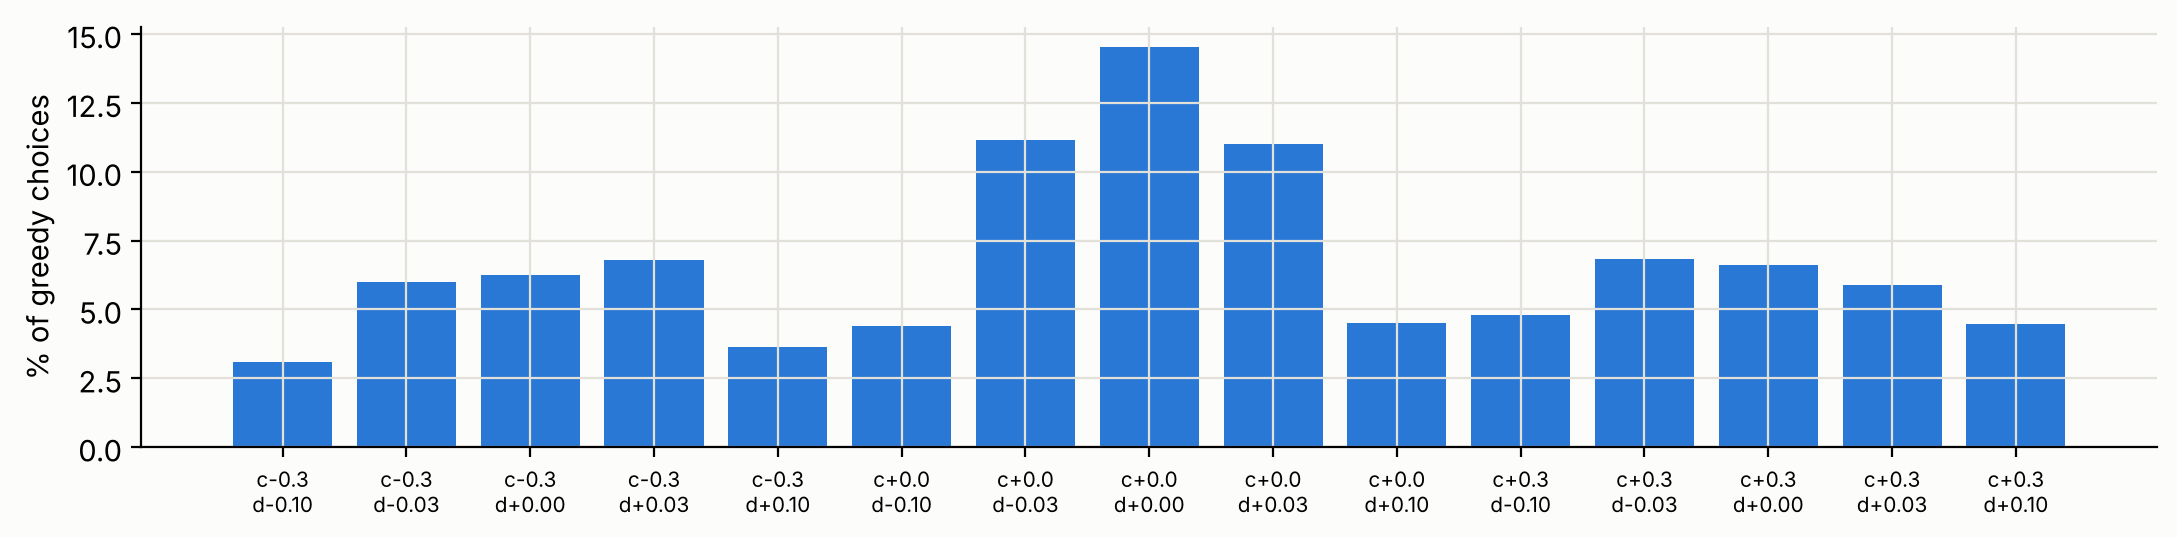

In [19]:
h = QDR[("quad", "DQN 25 Hz, all four", 0)]["act_hist"]; h = h / h.sum()
labels = [f"c{c:+.1f}\nd{d:+.2f}" for c in (-0.3, 0.0, 0.3) for d in (-0.10, -0.03, 0.0, 0.03, 0.10)]
plt.figure(figsize=(11, 2.8)); plt.bar(range(15), 100 * h, color=BLUE); plt.xticks(range(15), labels, fontsize=7.5)
plt.ylabel("% of greedy choices"); plt.tight_layout(); plt.show()

## 9. Protocol — what to remember

1. **A time-out is not a terminal state.** Bootstrap from the final observation; mask only true terminations.
2. **Replay buffer and target network are not optional.** Without the target network Q diverged by more than five orders
   of magnitude; with a 1 k buffer learning stalled.
3. **The target period is a speed/stability dial.** Too often → divergence; too rarely → value crawls one step per copy.
4. **Max over noisy estimates is biased upward** — by 1.7 σ with 15 actions. Double DQN removes it at zero cost; whether
   bias is what limits *your* run is something to measure (Q vs realised return), not assume.
5. **Add extensions one at a time, with ≥ 3 seeds.** Together they solved CartPole on every seed; n-step did most of the
   work, and dueling alone hurt.
6. **For continuous control, the action menu and decision rate are part of the design**, and they trade precision against
   chatter and compute.
7. **DQN is sample-efficient, PPO is smooth.** Replay roughly halved the experience needed on the quad; continuous actions cut
   chatter by an order of magnitude.
8. **Log max-Q, |TD error| and gradient norm**, not just return. Each failure mode has a signature.

## 10. Exercises

1. **Polyak targets.** Replace the hard copy with $\theta^- \leftarrow (1-\tau)\theta^- + \tau\theta$. Find the $\tau$ that
   matches "copy every 100 updates" and compare stability over 3 seeds.
2. **Remove one, not add one.** Run "all four" minus each component in turn. Is the ranking the same as the add-one ablation?
   Which component is *necessary* in combination?
3. **Make overestimation visible.** Add reward noise $\mathcal{N}(0, 1)$ to CartPole and give the agent 10 duplicated
   actions. Plot $\max_a Q(s_0,a)$ minus the realised return for vanilla vs Double DQN.
4. **n beyond 3.** Sweep $n \in \{1, 3, 5, 10, 20\}$ on CartPole. Where does the off-policy bias of long n-step targets start
   to hurt?
5. **The menu.** Train the quad with 9 actions ($d \in \{0, \pm0.05\}$) and with 25 actions. Report success, hover error,
   chatter and steps to 190. Is there a best menu size?
6. **Reduce chatter.** Raise the $|\Delta u|$ penalty from 0.05 to 0.2, or add a first-order filter on the commanded thrust.
   How much chatter can you remove before the hover error grows?
7. **Distributional DQN.** Replace the scalar Q head by C51 (Bellemare et al. 2017) or QR-DQN (Dabney et al. 2018), the one
   Rainbow component we left out. Does it help on CartPole?
8. **Same budget, same wall clock.** Give DQN and PPO the same wall-clock budget (not the same step budget) on the quad and
   repeat the comparison. Which wins now, and why?

## 11. References

* V. Mnih et al., "Human-level control through deep reinforcement learning," *Nature* 518, 529–533 (2015).
* H. van Hasselt, "Double Q-learning," *NeurIPS* 2010.
* H. van Hasselt, A. Guez, D. Silver, "Deep reinforcement learning with Double Q-learning," *AAAI* 2016.
* Z. Wang et al., "Dueling network architectures for deep reinforcement learning," *ICML* 2016.
* T. Schaul, J. Quan, I. Antonoglou, D. Silver, "Prioritized experience replay," *ICLR* 2016.
* M. Hessel et al., "Rainbow: Combining improvements in deep reinforcement learning," *AAAI* 2018.
* M. G. Bellemare, W. Dabney, R. Munos, "A distributional perspective on reinforcement learning," *ICML* 2017.
* C. Tallec, L. Blier, Y. Ollivier, "Making deep Q-learning methods robust to time discretization," *ICML* 2019.
* R. S. Sutton, A. G. Barto, *Reinforcement Learning: An Introduction*, 2nd ed., MIT Press 2018 — §6.5–6.7 (Q-learning,
  maximization bias, Double Q-learning), §11.3 (the deadly triad).
* A. G. Barto, R. S. Sutton, C. W. Anderson, "Neuronlike adaptive elements that can solve difficult learning control
  problems," *IEEE Trans. SMC* 13(5), 834–846 (1983) — CartPole.
* J. Schulman et al., "Proximal policy optimization algorithms," arXiv:1707.06347 (2017).
* PyTorch documentation, https://pytorch.org/docs/stable/ ; Gymnasium CartPole-v1, https://gymnasium.farama.org/

Generated by Claude and customized by

<div align="center">
<img src="https://raw.githubusercontent.com/dewdotninja/sharing-github/refs/heads/master/dewninja_logo50.jpg" alt="dewninja"/>
</div>
<div align="center">dew.ninja 2026</div>